# Evaluación, transferencia y límites: método en la práctica

**Nivel:** 2  
**Requisitos previos:** Evaluación, transferencia y límites nivel 1  
**Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Las ejecuciones nuevas de M01 y M04 reproducen los resultados bajo las mismas condiciones C01?


## Objetivos

Para el nivel 2 de evaluación y transferencia en C01, Reconstruye cómo una afirmación científica depende de la identidad de las trazas, los denominadores, las familias de tareas y las particiones de transferencia. Para el nivel 2 de evaluación y transferencia en C01, Una ejecución por caso ilustra un método; Para el nivel 2 de evaluación y transferencia en C01, las conclusiones de fiabilidad dependen de la matriz auditada completa y siguen limitadas a sus tareas diseñadas.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 2 de evaluación y transferencia en C01, El notebook lee artefactos comprometidos del producto. Para el nivel 2 de evaluación y transferencia en C01, Propietario: Para el nivel 2 de evaluación y transferencia en C01, Neuraxis. Para el nivel 2 de evaluación y transferencia en C01, Repositorio: Para el nivel 2 de evaluación y transferencia en C01, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 2 de evaluación y transferencia en C01, Apache-2.0. Para el nivel 2 de evaluación y transferencia en C01, El JSON es un artefacto experimental propio y congelado; Para el nivel 2 de evaluación y transferencia en C01, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 2 de evaluación y transferencia en C01, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 2 de evaluación y transferencia en C01, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 2 de evaluación y transferencia en C01, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 2 de evaluación y transferencia en C01, El manifiesto de publicación verifica los hashes. Para el nivel 2 de evaluación y transferencia en C01, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 2 de evaluación y transferencia en C01, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/research.json`
- `data/derived/semantic-transfer/index.json`
- `data/derived/semantic-transfer/report.json`
- `data/derived/episodes/M01-C01-nominal-40000.json`
- `data/derived/episodes/M04-C01-nominal-40000.json`
- `data/derived/episodes/M09-C01-nominal-40000.json`
- `data/derived/episodes/M12-C01-nominal-40000.json`


## Método

Para el nivel 2 de evaluación y transferencia en C01, El núcleo contiene 14.400 episodios indexados, pero diez etiquetas de semilla no crean diez diseños independientes cuando los resultados se repiten exactamente. Para el nivel 2 de evaluación y transferencia en C01, El hash verifica bytes e identidades; Para el nivel 2 de evaluación y transferencia en C01, no vuelve representativa una tarea. Para el nivel 2 de evaluación y transferencia en C01, La transferencia semántica cambia nombres y composiciones de operaciones, mientras la transferencia estructural y la ruta emparejada son carriles separados con su propio linaje. Para el nivel 2 de evaluación y transferencia en C01, Mantén separados los denominadores e inspecciona fallos por familia antes de promediar. Para el nivel 2 de evaluación y transferencia en C01, Los datos publicados muestran un núcleo saturado donde cinco métodos resuelven los 1.200 resultados y una pequeña muestra semántica donde M04 supera a M12. Para el nivel 2 de evaluación y transferencia en C01, Esto debilita una afirmación de superioridad; Para el nivel 2 de evaluación y transferencia en C01, no demuestra que un método sea universalmente mejor. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, El índice de episodios sirve para auditoría, no define por sí solo la unidad inferencial. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, familia, variante y semilla determinan qué resultados son independientes y cuáles comparten entorno. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, Incluye todos los intentos en el denominador, conserva fallos y separa casos centrales de composiciones retenidas antes de calcular éxito o intervalos de confianza. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, Si los resultados son idénticos entre semillas, el intervalo por semilla es degenerado. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, la incertidumbre debe reflejar variación entre familias o declarar que no existe intervalo empírico. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, Una afirmación de transferencia necesita particiones sin composiciones casi duplicadas, plantillas compartidas ni etiquetas filtradas entre entrenamiento y evaluación. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, La conclusión reproducible queda acotada a las operaciones medidas, artefactos publicados y supuestos del entorno. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, no se generaliza a autonomía abierta sin evidencia nueva. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, En este nivel, separa núcleo, transferencia y ablación, e informa familias, variantes, semillas y episodios fallidos detrás de cada agregado. Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, para evaluación y transferencia en C01, Una extensión útil reconstruye el denominador desde el manifiesto y verifica que la partición retenida excluya composiciones relacionadas antes de comparar métodos.


### evaluación y transferencia · nivel 2 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M04", "M09", "M12"]
trace_methods = ["M01", "M04", "M09", "M12"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### evaluación y transferencia · nivel 2 — Ejecuta las políticas publicadas y compara la corrida


### evaluación y transferencia · nivel 2 — Compara la secuencia completa y no solo la primera acción


### evaluación y transferencia · L2 — Construir la primera política ejecutable

En el nivel 2, construye M01 para evaluación y transferencia con la fábrica pública y conserva su contrato de observación antes de muestrear C01.


In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### evaluación y transferencia · L2 — Ejecutar el método principal en el caso indicado

En el nivel 2 de evaluación y transferencia, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### evaluación y transferencia · L2 — Construir una política de comparación independiente

Para el nivel 2 de evaluación y transferencia, crea M04 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### evaluación y transferencia · L2 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 2 ejecuta M04 en el mismo C01, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### evaluación y transferencia · L2 — Agregar los dos episodios ejecutados

En el nivel 2, el agregador resume dos episodios ejecutados de evaluación y transferencia, and las afirmaciones entre familias aún requieren el benchmark completo.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### evaluación y transferencia · L2 — Resultados de políticas nuevas

Para el nivel 2 de evaluación y transferencia en C01, El gráfico siguiente se calcula con los resultados de episodios de evaluación y transferencia recién ejecutados en C01, no se copia de un artefacto congelado.


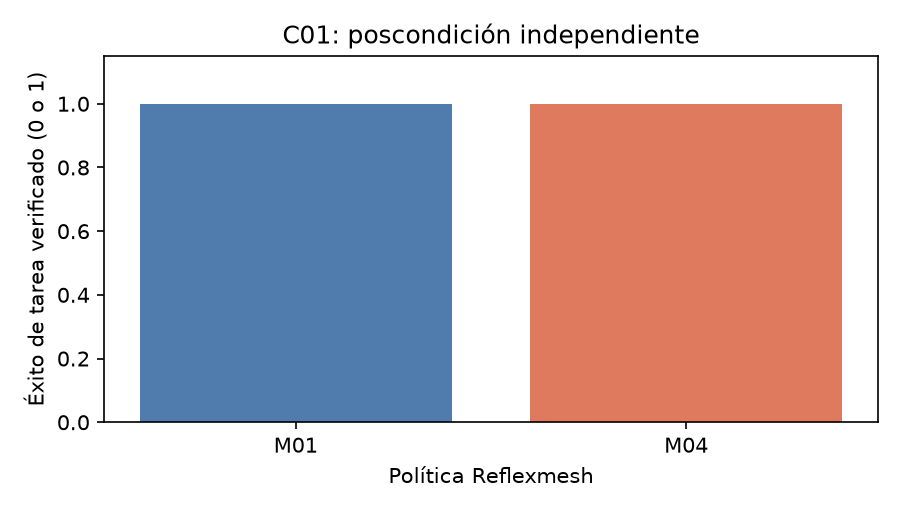

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 2 de evaluación y transferencia en C01, Para evaluación y transferencia, estas barras muestran resultados nuevos de poscondición de M01 y M04 en C01; Para el nivel 2 de evaluación y transferencia en C01, éxito vale 1 y falla 0. Para el nivel 2 de evaluación y transferencia en C01, Lee el caso y la semilla antes de compararlas. Para el nivel 2 de evaluación y transferencia en C01, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


### evaluación y transferencia · L2 | Tiempo registrado del controlador

En el nivel 2, la figura de tiempos de evaluación y transferencia usa registros congelados y verificados por hash para M01 y M04 en C01, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 2 para evaluación y transferencia describe el entorno registrado bajo su caso, variante y semilla declarados.

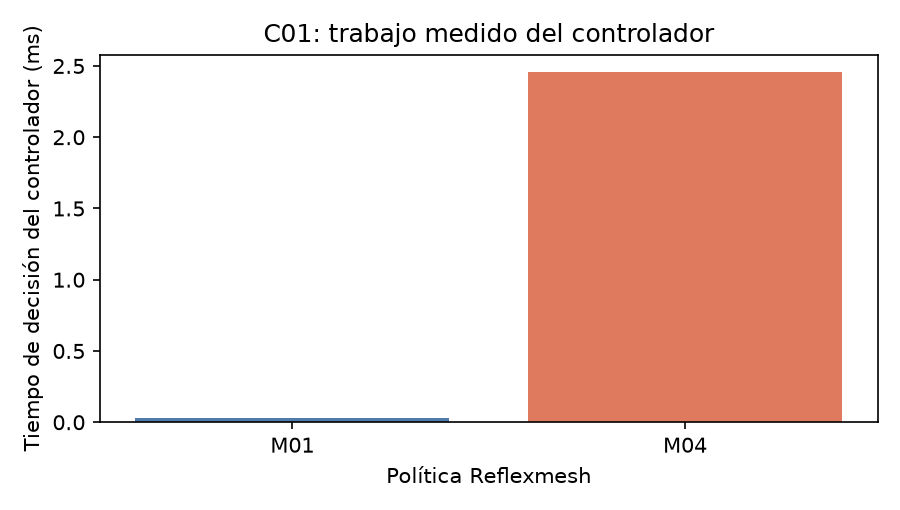

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: trabajo medido del controlador")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 2 para evaluación y transferencia lee registros canónicos de M01/M04 en C01, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En esta lección de evaluación y transferencia, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de evaluación y transferencia ejecuta 2 episodios nuevos de M01 y M04 bajo condiciones C01 idénticas; conserva a la vista las familias y semillas de evaluación y transferencia, porque la matriz contiene tareas diseñadas y no una muestra poblacional.

Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, La matriz central está saturada: Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, siete métodos resuelven los 1.200 episodios y solo 71/1.440 celdas método/caso/variante cambian por semilla. Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, En transferencia estructural, M04 resuelve 24/24 casos y M12 21/24; Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, el carril semántico opaco mayor también favorece M09 frente a M12. Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, No hay respaldo para afirmar superioridad aprendida.

Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Este paso de autoría no compromete salidas generadas; Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, Para el nivel 2 de evaluación y transferencia en C01, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 2 de evaluación y transferencia en C01, En el nivel 2, evaluación y transferencia usa C01 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 2 de evaluación y transferencia en C01, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682)
- [SWE](https://arxiv.org/abs/2310.06770)
- [TAU2](https://arxiv.org/abs/2506.07982)
